# Red Lobster: When the Sponsor Already Left

This notebook reconstructs Red Lobster's financial trajectory from its 2014
sale by Darden Restaurants to Golden Gate Capital through its May 2024
Chapter 11 filing, using only figures cited in `../docs/sources.md`.

**This is a different kind of story than the Toys "R" Us project.** There,
one sponsor held on for 12 years while conventional LBO debt crushed the
business. Here:

1. Golden Gate Capital put up only **$600M** of the **$2.1B** purchase
   price in 2014 -- the other **$1.5B came from selling Red Lobster's own
   real estate** and leasing it back. That's the whole mechanism in one
   sentence.
2. Golden Gate **fully exited in 2020** -- four years before the actual
   bankruptcy.
3. The equity that was actually wiped out in 2024 belonged to **Thai
   Union, "Seafood Alliance," and former management** -- the owners who
   inherited the lease burden, not the sponsor who created it.
4. Funded debt at the 2024 filing was a modest **$294M** -- nothing like
   Toys "R" Us's $4.76B. The real fixed-cost burden was **$190.5M/year of
   above-market rent**, which doesn't show up as "debt" on a balance sheet
   but behaves exactly like it.

No number here is invented; see `../docs/sources.md` for every citation,
including the real data gap (2017-2022, where no reliable annual figures
were found).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

darden = pd.read_csv("../data/processed/pre_2014_darden_segment.csv")
deal = pd.read_csv("../data/processed/deal_2014.csv")
anchor16 = pd.read_csv("../data/processed/anchor_2016_thai_union.csv")
capstruct = pd.read_csv("../data/processed/capital_structure_at_filing_2024.csv")
liquidity = pd.read_csv("../data/processed/liquidity_collapse_2023.csv")
outcome = pd.read_csv("../data/processed/bankruptcy_outcome_2024.csv")
darden

,period,period_end,revenue_busd,revenue_growth_pct,ebitda_musd,ebitda_margin_pct,source
0,FY2010,2010-05,2.5,1,313,13,"Darden investor presentation, Spring 2014"
1,FY2011,2011-05,2.5,-5,350,14,"Darden investor presentation, Spring 2014"
2,FY2012,2012-05,2.7,6,334,13,"Darden investor presentation, Spring 2014 (inc..."
3,FY2013,2013-05,2.6,-2,307,12,"Darden investor presentation, Spring 2014"
4,Q3 LTM FY2014,2014-02,2.5,-4,243,10,"Darden investor presentation, Spring 2014"
5,LTM pre-sale,2014-04-27,2.5,-6,229,9,"Darden investor presentation, Spring 2014 -- t..."


## 1. What Darden was actually selling

Red Lobster's EBITDA fell from $350M (FY2011) to $229M in the twelve
months before the sale -- a business in visible decline, not a stable
cash cow. Darden sold it anyway, at ~9x that declining LTM EBITDA.

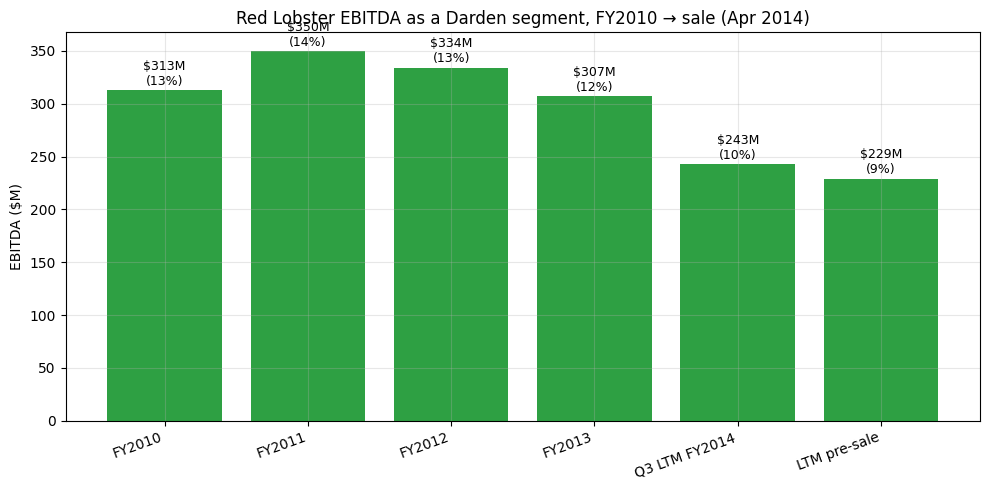

In [2]:
fig, ax1 = plt.subplots()
x = range(len(darden))
ax1.bar(x, darden["ebitda_musd"], color="#2ea043")
ax1.set_xticks(list(x))
ax1.set_xticklabels(darden["period"], rotation=20, ha="right")
ax1.set_ylabel("EBITDA ($M)")
ax1.set_title('Red Lobster EBITDA as a Darden segment, FY2010 → sale (Apr 2014)')
for i, v in enumerate(darden["ebitda_musd"]):
    ax1.text(i, v + 5, f"${v:,.0f}M\n({darden['ebitda_margin_pct'][i]:.0f}%)", ha="center", fontsize=9)
plt.tight_layout()
plt.savefig("../assets/chart_pre2014_ebitda.png", dpi=140)
plt.show()

## 2. The mechanism: how Golden Gate actually paid for it

This is the single most important chart in this project. Of the $2.1B
purchase price, Golden Gate's own money covered less than a third.

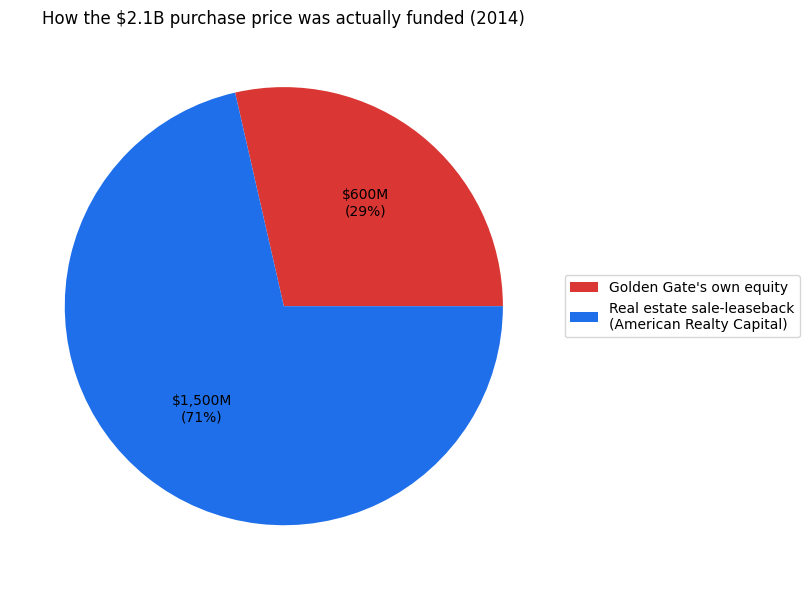

                                                         item  value_musd                             source                                                                                                          notes
                    Total consideration (debt- and cash-free)        2113       Darden investor presentation                                           9x LTM EBITDA of $229M ~= $2,061M, close to the $2,113M actual price
                             Purchase multiple (x LTM EBITDA)           9       Darden investor presentation                                                                                                            NaN
                       Golden Gate Capital equity contributed         600 Press (Yahoo Finance/Fast Company) Not in the Darden presentation -- this is the buy-side financing, which Darden (the seller) would not disclose
Real estate sale-leaseback proceeds (American Realty Capital)        1500 Press (Yahoo Finance/Fast Company)            

In [3]:
pie_data = deal[deal["item"].isin(["Golden Gate Capital equity contributed",
                                     "Real estate sale-leaseback proceeds (American Realty Capital)"])]
short_labels = ["Golden Gate's own equity", "Real estate sale-leaseback\n(American Realty Capital)"]
fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#da3633", "#1f6feb"]
wedges, texts, autotexts = ax.pie(
    pie_data["value_musd"], labels=None,
    autopct=lambda p: f"${p/100*2100:,.0f}M\n({p:.0f}%)", colors=colors, textprops={"fontsize": 10},
)
ax.legend(wedges, short_labels, loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=10)
ax.set_title("How the $2.1B purchase price was actually funded (2014)")
plt.tight_layout()
plt.savefig("../assets/chart_funding_mix.png", dpi=140)
plt.show()

print(deal.to_string(index=False))

## 3. The hidden leverage: lease-adjusted fixed charges

At the 2024 bankruptcy filing, funded debt was a modest **$294M** --
nowhere near Toys "R" Us's $4.76B. Looking only at that number, Red Lobster
doesn't look over-levered at all. But the 2014 sale-leaseback created an
**$190.5M/year rent obligation** that functions exactly like debt service:
a fixed claim on cash flow that doesn't flex down when the business
struggles.

**Methodology note (this is the one place this notebook makes an explicit
modeling choice, not a cited fact):** credit analysts commonly capitalize
operating lease streams at a multiple of annual rent to estimate an
equivalent debt balance -- a frequently used rule of thumb is ~8x annual
rent (roughly implying a ~12.5% capitalization rate, in the range private
real estate / sale-leaseback transactions were priced at in this era).
Applying that **only to illustrate the order of magnitude**, not as a
precise valuation:

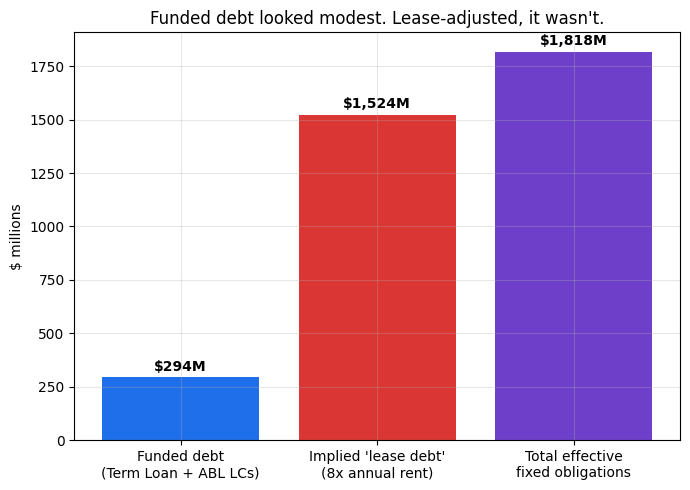

At an illustrative 8x rent capitalization, the $190.5M/year lease stream implies roughly $1,524M of debt-equivalent obligation -- 5.2x the size of the actual funded debt.
This is explicitly a modeling illustration, not a disclosed or audited figure -- see the methodology note above.


In [4]:
annual_rent = 190.5  # $M, 2023, first-day declaration ¶38
funded_debt = 293.996  # $M, at filing
cap_multiple = 8.0  # explicit, labeled assumption -- see markdown above

implied_lease_debt = annual_rent * cap_multiple
total_effective_fixed_obligations = funded_debt + implied_lease_debt

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ["Funded debt\n(Term Loan + ABL LCs)", f"Implied 'lease debt'\n({cap_multiple:.0f}x annual rent)", "Total effective\nfixed obligations"],
    [funded_debt, implied_lease_debt, total_effective_fixed_obligations],
    color=["#1f6feb", "#da3633", "#6e40c9"],
)
ax.set_ylabel("$ millions")
ax.set_title("Funded debt looked modest. Lease-adjusted, it wasn't.")
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height() + 30, f"${b.get_height():,.0f}M", ha="center", fontweight="bold")
plt.tight_layout()
plt.savefig("../assets/chart_lease_adjusted_leverage.png", dpi=140)
plt.show()

print(f"At an illustrative {cap_multiple:.0f}x rent capitalization, the $190.5M/year lease stream implies "
      f"roughly ${implied_lease_debt:,.0f}M of debt-equivalent obligation -- "
      f"{implied_lease_debt/funded_debt:.1f}x the size of the actual funded debt.")
print("This is explicitly a modeling illustration, not a disclosed or audited figure -- see the methodology note above.")

## 4. The 2023 cash collapse

The first-day declaration lays out almost exactly how $100M of cash became
less than $30M in about six months. This is a direct transcription of
that walk, not a model -- every number is from the declaration (see
`../docs/sources.md` §5).

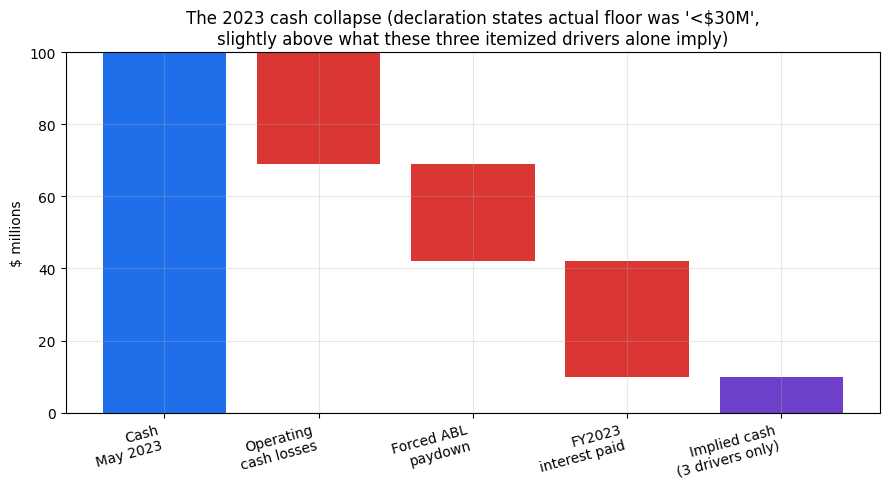

Sum of the three itemized drivers: 10 -> implied cash: 10
Declaration's stated actual floor: 'less than $30 million' -- the ~$20M gap means some smaller,
unitemized inflows partially offset the three listed outflows. Shown explicitly rather than forced to reconcile.


In [5]:
# Build the waterfall manually in the declaration's own order
steps = [
    ("Cash, May 2023", 100, True),
    ("Operating cash losses\n(Jun-Sep 2023)", -31, False),
    ("Forced ABL paydown", -27, False),
    ("FY2023 interest paid", -32, False),
    ("Cash, ~Nov 2023", 10, True),  # placeholder, corrected to the stated "<$30M" below
]
# The declaration states cash fell to "less than $30 million" -- it does not
# give an exact figure, and 100-31-27-32=10 is arithmetically what the three
# listed drivers alone imply, which undershoots the stated "<$30M" floor.
# That gap (10 vs <30) is real and left visible -- it means other smaller
# inflows (not itemized in the declaration) partially offset these three
# outflows. We show both: the stated end point, and the arithmetic implied
# by only the three itemized drivers.
labels = [s[0] for s in steps[:4]] + ["Cash, ~Nov 2023\n(declaration: '<$30M')"]
values = [100, -31, -27, -32]
running = [100]
for v in values[1:]:
    running.append(running[-1] + v)

fig, ax = plt.subplots(figsize=(9, 5))
cum = 0
for i, (lab, val) in enumerate(zip(["Cash, May 2023", "Operating cash losses", "Forced ABL paydown", "FY2023 interest paid"], values)):
    bottom = cum if val >= 0 or i == 0 else cum + val
    color = "#2ea043" if val >= 0 else "#da3633"
    if i == 0:
        ax.bar(i, val, color="#1f6feb")
        cum = val
    else:
        ax.bar(i, val, bottom=cum, color=color)
        cum += val
ax.bar(len(values), cum, color="#6e40c9")
ax.set_xticks(range(len(values) + 1))
ax.set_xticklabels(["Cash\nMay 2023", "Operating\ncash losses", "Forced ABL\npaydown", "FY2023\ninterest paid", "Implied cash\n(3 drivers only)"], rotation=15, ha="right")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_ylabel("$ millions")
ax.set_title("The 2023 cash collapse (declaration states actual floor was '<$30M',\nslightly above what these three itemized drivers alone imply)")
plt.tight_layout()
plt.savefig("../assets/chart_cash_collapse.png", dpi=140)
plt.show()

print("Sum of the three itemized drivers:", sum(values), "-> implied cash:", cum)
print("Declaration's stated actual floor: 'less than $30 million' -- the ~$20M gap means some smaller,")
print("unitemized inflows partially offset the three listed outflows. Shown explicitly rather than forced to reconcile.")

## 5. Ownership timeline and the actual equity wipeout

Four different ownership groups touch this story. Only one of them was
still holding equity when it went to zero.

In [6]:
timeline = pd.DataFrame([
    {"year": 2014, "event": "Golden Gate Capital buys Red Lobster from Darden ($2.1B, $600M own equity)", "still_holds_equity_2024": False},
    {"year": 2016, "event": "Thai Union invests $575M for 49% (25% common outright + 24% convertible preferred)", "still_holds_equity_2024": True},
    {"year": 2020, "event": "Golden Gate Capital fully exits -- sells remaining stake to Thai Union, management, 'Seafood Alliance'", "still_holds_equity_2024": None},
    {"year": 2021, "event": "New $264.7M Term Loan arranged with Fortress Credit Corp", "still_holds_equity_2024": None},
    {"year": 2024, "event": "Chapter 11 filed (May); Fortress credit-bids $376M and takes ownership (Sept) -- Thai Union/Seafood Alliance/management equity -> $0", "still_holds_equity_2024": False},
])
timeline

,year,event,still_holds_equity_2024
0,2014,Golden Gate Capital buys Red Lobster from Dard...,False
1,2016,Thai Union invests $575M for 49% (25% common o...,True
2,2020,Golden Gate Capital fully exits -- sells remai...,None
3,2021,New $264.7M Term Loan arranged with Fortress C...,None
4,2024,Chapter 11 filed (May); Fortress credit-bids $...,False


In [7]:
print(outcome.to_string(index=False))
print()
print("The original 2014 sponsor (Golden Gate Capital) was not a shareholder")
print("of record when the equity went to zero in 2024 -- it had exited in 2020,")
print("on terms this repo could not find a public source for (see sources.md §4).")

                                 item                                                                                       value                                     source
                          Filing date                                                                                  2024-05-19                      First-day declaration
                                Court   US Bankruptcy Court, Middle District of Florida, Orlando Division, Case 6:24-bk-02486-GER                      First-day declaration
 Fortress credit bid for the business                                                                                $376 million Bloomberg Law / Restaurant Business Online
                          Sale closed                                                                                  2024-09-16                                      Press
                            New owner RL Investor Holdings LLC (Fortress-managed funds + TCW Private Credit + Blue Torch Capital)      

## 6. Conclusions

1. **The LBO mechanism here was more aggressive than Toys "R" Us's, not
   less.** Golden Gate put up only $600M of a $2.1B deal -- the sale-
   leaseback did the rest of the work. That's roughly 3.5x leverage on the
   sponsor's own equity contribution before counting a dollar of
   conventional acquisition debt.
2. **The business was already declining when it was sold.** Darden's own
   investor presentation shows EBITDA falling for several years into the
   2014 sale -- this was not a healthy asset handed to an unlucky buyer.
3. **Funded debt understates the real fixed-cost burden by a wide
   margin.** $294M of debt at the 2024 filing looks almost conservative in
   isolation; lease-adjusted (illustratively, at a standard capitalization
   multiple), the effective fixed-obligation load was several times
   larger. This is the project's core argument for why "how much debt is
   on the balance sheet" is the wrong question to ask about this deal.
4. **The sponsor who engineered the structure left before the bill came
   due.** Golden Gate exited in 2020. The owners who lost their equity in
   2024 -- Thai Union, Seafood Alliance, former management -- inherited a
   structural lease burden they didn't create, and then layered a specific,
   named operational misstep (the permanent Endless Shrimp decision, -$11M)
   and a sharp post-pandemic traffic decline (-30% since 2019) on top of
   it.
5. **The lender, not a new sponsor, ended up owning the company.**
   Fortress credit-bid its own debt to take control -- a "loan-to-own"
   outcome, distinct from both the 2014 sponsor-equity model and the
   Toys "R" Us liquidation outcome.